# Topic Sentiment and Business Insights

Combine topic assignments with sentiment labels, hotels and dates. This presents evidence-based summaries for a dashboard and business report.

In [ ]:
# Import all Libraries
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

### Load Topic Assignments

In [ ]:
# Load file paths
TOPIC_FILE = Path("../Dataset/processed_data/reviews_with_topics.csv")
CLEAN_FILE = Path("../Dataset/cleaned_data/cleaned_montra_data.csv")

topic = pd.read_csv(TOPIC_FILE)
clean = pd.read_csv(CLEAN_FILE)

print("Rows:", len(topic), len(clean))
print("Topic columns:", topic.columns.tolist())
print("Clean columns:", clean.columns.tolist())
print("Shared columns:", sorted(set(topic.columns) & set(clean.columns)))

Rows: 35000 35000
Topic columns: ['review_text', 'topic_id', 'topic_name']
Clean columns: ['review_id', 'booking_id', 'guest_id', 'hotel_id', 'review_text', 'rating_score', 'review_date', 'sentiment_label', 'room_type', 'booking_channel', 'check_in_date', 'check_out_date', 'total_amount', 'stay_duration', 'customer_type', 'country', 'previous_stays', 'hotel_name', 'location', 'star_rating', 'total_rooms', 'light_text', 'heavy_text', 'n_words', 'label']
Shared columns: ['review_text']


In [29]:
key = ["review_text"]            # add "review_date", "hotel_id" etc. if both files have them

topic_u = topic.drop_duplicates(subset=key)
clean_u = clean.drop_duplicates(subset=key)

analytics_data = topic_u.merge(clean_u[key + ["sentiment_label"]], on=key, how="left", validate="1:1")
print("Rows:", len(analytics_data), "| without label:", analytics_data["sentiment_label"].isna().sum())

Rows: 34175 | without label: 34175


In [30]:
topic = pd.read_csv(TOPIC_FILE)
clean = pd.read_csv(CLEAN_FILE)

for col in ["review_text", "light_text", "heavy_text"]:
    same = (topic["review_text"].astype(str).values == clean[col].astype(str).values)
    print(f"topic.review_text vs clean.{col}: {same.mean():.1%} of rows identical")

topic.review_text vs clean.review_text: 0.0% of rows identical
topic.review_text vs clean.light_text: 0.0% of rows identical
topic.review_text vs clean.heavy_text: 59.9% of rows identical


In [32]:
t = topic["review_text"].astype(str).str.strip().values
h = clean["heavy_text"].astype(str).str.strip().values
same = (t == h)

# 1) Is the match rate steady along the file, or does it collapse at some point?
print(pd.Series(same).groupby(np.arange(len(same)) // 3500).mean().round(2))

# 2) What do the non-matching rows look like?
diff = pd.DataFrame({"topic_text": t, "heavy_text": h})[~same]
pd.set_option("display.max_colwidth", 120)
display(diff.head(10))

# 3) For non-matching rows, do they still share most of their words? (same review, different cleaning)
def overlap(a, b):
    a, b = set(a.split()), set(b.split())
    return len(a & b) / max(1, len(a | b))

ov = np.array([overlap(a, b) for a, b in zip(t[~same], h[~same])])
print("\nNon-matching rows with word overlap > 0.6:", (ov > 0.6).mean().round(3))

0    0.59
1    0.60
2    0.61
3    0.60
4    0.59
5    0.61
6    0.61
7    0.60
8    0.60
9    0.59
dtype: float64


,topic_text,heavy_text
6,couldn asked better base visiting plus overall restaurant write home expected genuinely impressed arrival experience...,couldn asked better base visiting london plus overall restaurant write home expected genuinely impressed arrival exp...
7,wonderful time stay plus surrounding area exceeded expectation ideally situated restaurant shop nearby,wonderful time stay nottingham plus surrounding area exceeded expectation ideally situated restaurant shop nearby
11,hotel time truly memorable genuinely impressed pool impressively modern said restaurant stood worth waking early pas...,hotel time london truly memorable genuinely impressed pool impressively modern said restaurant stood worth waking ea...
13,wasn experience expected visit overall price left lot desired quality didn match price tag overall restaurant accept...,wasn experience expected visit glasgow overall price left lot desired quality didn match price tag overall restauran...
18,couldn asked better base visiting plus surrounding area very convenient public transport link right outside overall ...,couldn asked better base visiting edinburgh plus surrounding area very convenient public transport link right outsid...
19,wonderful time stay honestly housekeeping staff incredibly friendly booking time town,wonderful time stay edinburgh honestly housekeeping staff incredibly friendly booking time town
21,stay didn planned room left lot desired stain point staff,stay nottingham didn planned room left lot desired stain point staff
22,stay fairly ordinary concierge fairly professional paid,stay glasgow fairly ordinary concierge fairly professional paid
25,time got rocky start addition surrounding area left lot desired took age reach city center,time edinburgh got rocky start addition surrounding area left lot desired took age reach city center
27,hotel fine unremarkable choice time said check desk average ordinary happened plus bathroom passably clean paid,hotel fine unremarkable choice time brighton said check desk average ordinary happened plus bathroom passably clean ...



Non-matching rows with word overlap > 0.6: 1.0


In [33]:
assert len(topic) == len(clean)
assert (ov > 0.6).mean() > 0.95, "Too many rows look misaligned"

analytics_data = topic.copy()
for col in ["review_id", "hotel_id", "hotel_name", "review_date", "rating_score", "sentiment_label", "label"]:
    analytics_data[col] = clean[col].values

analytics_data.to_csv("../Dataset/processed_data/reviews_with_topics_and_sentiment.csv", index=False)

In [ ]:
# Define file paths for concatenation
TOPIC_FILE = Path("../Dataset/processed_data/reviews_with_topics_and_sentiment.csv")
CLEAN_FILE = Path("../Dataset/cleaned_data/cleaned_montra_data.csv")

# Load the available dataset
if TOPIC_FILE.exists():
    analytics_data = pd.read_csv(TOPIC_FILE)
    print("Loaded reviews with topics.")
elif CLEAN_FILE.exists():
    analytics_data = pd.read_csv(CLEAN_FILE)
    print("Topic file not found. Loaded cleaned reviews instead.")
else:
    raise FileNotFoundError(
        "Neither the topic file nor the cleaned review file was found. "
        "Check your file paths.")

# Convert review dates to datetime
if "review_date" in analytics_data.columns:
    analytics_data["review_date"] = pd.to_datetime(
        analytics_data["review_date"], errors="coerce")

# Standardise sentiment labels
if "sentiment_label" in analytics_data.columns:
    analytics_data["sentiment_label"] = (
        analytics_data["sentiment_label"].astype(str).str.lower().str.strip())

# Display the first 10 rows
display(analytics_data.head(10))

# Check dataset size and columns
print("Dataset shape:", analytics_data.shape)
print("Columns:", analytics_data.columns.tolist())

Loaded reviews with topics.


,review_text,topic_id,topic_name,review_id,hotel_id,hotel_name,review_date,rating_score,sentiment_label,label
0,overall price fair paid consider not,0,Room Cleanliness,1,18,The Aberdeen Grand,2025-06-02,3.2,neutral,positive
1,room ordinary paid overall price exceeded expectation great deal quality easily matched price,0,Room Cleanliness,2,23,Nottingham Park Hotel,2025-01-22,4.0,positive,positive
2,unfortunately pool outdated clearly needed upkeep wouldn recommend,2,Food and Breakfast,3,13,The London Boutique,2025-03-13,1.9,negative,negative
3,disappointed neighborhood disappointingly way sadly room turned grimy,2,Food and Breakfast,4,12,Manchester Metropolitan,2026-03-18,2.2,negative,positive
4,room service standard hotel fare paid said bedding decent shape paid cost stay reasonable paid,0,Room Cleanliness,5,5,Glasgow Metropolitan,2025-03-03,3.3,neutral,positive
5,getting hotel unsafe area really affected stay said check process delayed clear reason really affected stay,2,Food and Breakfast,6,13,The London Boutique,2025-03-03,1.8,negative,negative
6,couldn asked better base visiting plus overall restaurant write home expected genuinely impressed arrival experience...,5,Other Topics,7,2,The London Heritage,2025-03-22,4.3,positive,positive
7,wonderful time stay plus surrounding area exceeded expectation ideally situated restaurant shop nearby,1,Staff and Customer Service,8,11,Nottingham Riverside Hotel,2025-07-19,3.5,positive,positive
8,house cafe acceptable paid said gym basic but functional paid,0,Room Cleanliness,9,16,Glasgow Skyline Hotel,2026-01-24,2.6,neutral,positive
9,manager fine special paid fitness facility special did job surprise,3,Location and Accessibility,10,22,The Belfast Heritage,2026-03-12,3.1,neutral,positive


Dataset shape: (35000, 10)
Columns: ['review_text', 'topic_id', 'topic_name', 'review_id', 'hotel_id', 'hotel_name', 'review_date', 'rating_score', 'sentiment_label', 'label']


### Topic Sentiment Table

In [35]:
# Summarise sentiment by topic
if "topic_id" in analytics_data.columns:

    # Remove rows with missing topic or sentiment
    topic_data = analytics_data.dropna(
        subset=["topic_id", "sentiment_label"]).copy()

    # Count reviews for each sentiment in each topic
    topic_sentiment_counts = pd.crosstab(
        topic_data["topic_id"],
        topic_data["sentiment_label"])

    # Calculate sentiment percentages within each topic
    topic_sentiment_percent = (pd.crosstab( topic_data["topic_id"],
            topic_data["sentiment_label"], normalize="index") * 100).round(2)

    # Combine counts and percentages
    topic_summary = topic_sentiment_counts.add_prefix("count_").join(
        topic_sentiment_percent.add_prefix("percent_"))

    # Add total reviews per topic
    topic_summary["total_reviews"] = topic_sentiment_counts.sum(axis=1)

    # Display largest topics first
    topic_summary = topic_summary.sort_values("total_reviews", ascending=False)

    display(topic_summary)

else:
    print("topic_id is missing. Run notebook 04 first.")

sentiment_label,count_negative,count_neutral,count_positive,percent_negative,percent_neutral,percent_positive,total_reviews
topic_id,,,,,,,
0,1001,9614,1176,8.49,81.54,9.97,11791
1,128,737,8683,1.34,7.72,90.94,9548
2,7166,648,121,90.31,8.17,1.52,7935
3,576,757,598,29.83,39.20,30.97,1931
4,77,1497,78,4.66,90.62,4.72,1652
5,1,45,1126,0.09,3.84,96.08,1172
6,914,57,0,94.13,5.87,0.00,971


### Negative Feedback by Hotel

In [36]:
# Check that the required columns exist
if {"hotel_name", "sentiment_label"}.issubset(analytics_data.columns):

    # Summarise reviews for each hotel
    hotel_summary = analytics_data.groupby("hotel_name").agg(
        total_reviews=("sentiment_label", "count"),
        negative_reviews=("sentiment_label", lambda x: (x == "negative").sum())
    )

    # Calculate negative review percentage
    hotel_summary["negative_rate_percent"] = (
        hotel_summary["negative_reviews"]
        / hotel_summary["total_reviews"] * 100
    ).round(2)

    # Keep hotels with at least 10 reviews
    hotel_summary = hotel_summary[
        hotel_summary["total_reviews"] >= 10
    ]

    # Rank hotels by negative review rate
    hotel_summary = hotel_summary.sort_values(
        "negative_rate_percent", ascending=False
    )

    display(hotel_summary)

else:
    print("hotel_name or sentiment_label is missing.")

,total_reviews,negative_reviews,negative_rate_percent
hotel_name,,,
Edinburgh Riverside Hotel,2909,1026,35.27
The Glasgow Heritage,1354,473,34.93
Glasgow Skyline Hotel,1445,504,34.88
The Oxford Boutique,1405,481,34.23
Glasgow Harbour Hotel,1385,466,33.65
The Leeds Grand,1373,460,33.50
The Brighton Heritage,1399,465,33.24
Leicester Harbour Hotel,1353,447,33.04
Manchester Metropolitan,1418,467,32.93


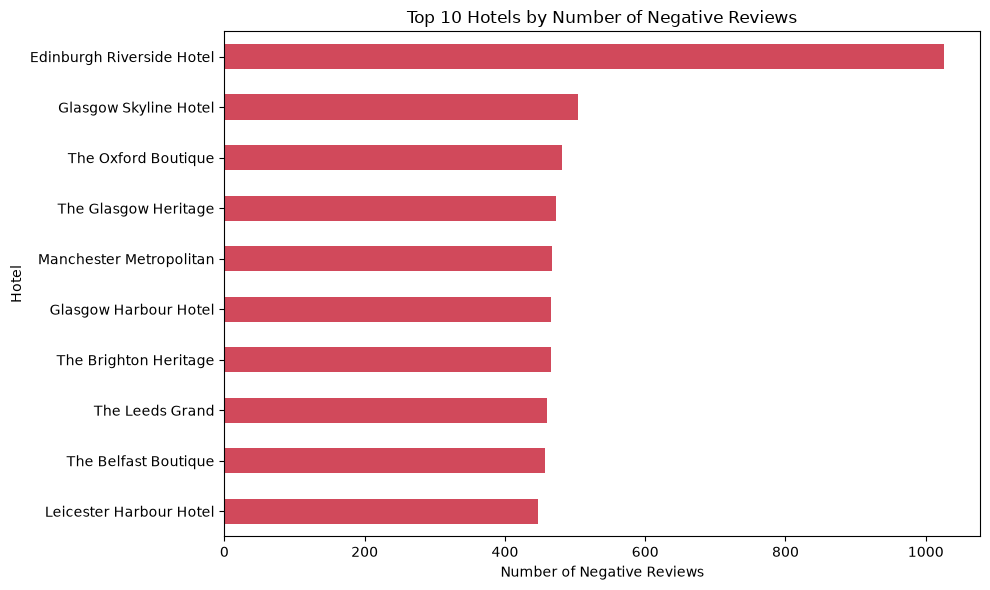

In [37]:
import matplotlib.pyplot as plt

# Check that the required columns exist
if {"hotel_name", "sentiment_label"}.issubset(analytics_data.columns):

    # Count negative reviews for each hotel
    top_10_negative = (
        analytics_data[analytics_data["sentiment_label"] == "negative"]
        .groupby("hotel_name")
        .size()
        .sort_values(ascending=False)
        .head(10)
        .sort_values()
    )

    # Plot the results
    plt.figure(figsize=(10, 6))
    top_10_negative.plot(kind="barh", color="#D1495B")

    plt.title("Top 10 Hotels by Number of Negative Reviews")
    plt.xlabel("Number of Negative Reviews")
    plt.ylabel("Hotel")
    plt.tight_layout()
    plt.show()

else:
    print("hotel_name or sentiment_label is missing.")

### Monthly Sentiment Trends

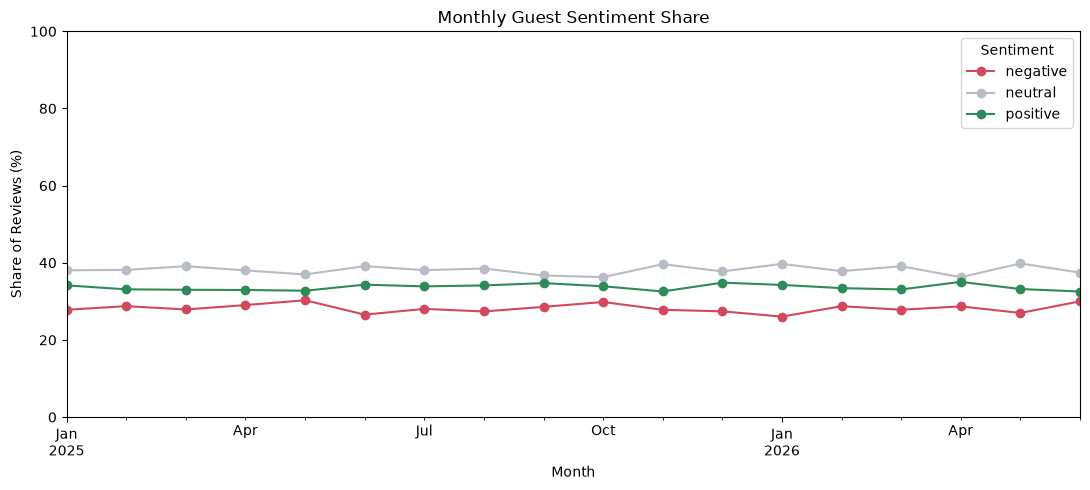

In [38]:
import pandas as pd
import matplotlib.pyplot as plt

# Check that the required columns exist
if {"review_date", "sentiment_label"}.issubset(analytics_data.columns):

    # Remove missing dates
    dated = analytics_data.dropna(subset=["review_date"]).copy()

    # Convert dates to datetime
    dated["review_date"] = pd.to_datetime(
        dated["review_date"], errors="coerce"
    )
    dated = dated.dropna(subset=["review_date"])

    # Group reviews by month
    dated["month"] = dated["review_date"].dt.to_period("M").dt.to_timestamp()

    # Calculate monthly sentiment percentages
    monthly = pd.crosstab(
        dated["month"],
        dated["sentiment_label"],
        normalize="index"
    ) * 100

    # Plot monthly sentiment share
    colors = {
        "negative": "#D1495B",
        "neutral": "#B8BCC4",
        "positive": "#2E8B57"
    }

    monthly = monthly.reindex(
        columns=["negative", "neutral", "positive"]
    )

    monthly.plot(
        figsize=(11, 5),
        marker="o",
        color=[colors[col] for col in monthly.columns]
    )

    plt.title("Monthly Guest Sentiment Share")
    plt.xlabel("Month")
    plt.ylabel("Share of Reviews (%)")
    plt.ylim(0, 100)
    plt.legend(title="Sentiment")
    plt.grid(False)
    plt.tight_layout()
    plt.show()

else:
    print("review_date or sentiment_label is missing.")

### Export Tables for PowerBI or  report documentation

In [39]:
# Create the output folder
OUT = Path("../reports/business_insights")
OUT.mkdir(parents=True, exist_ok=True)
RESULT_PATH = Path("../Results")
OUT.mkdir(parents=True, exist_ok=True)

# Save topic sentiment results
if "topic_id" in analytics_data.columns:

    if "topic_sentiment_counts" in globals():
        topic_sentiment_counts.to_csv(
            OUT / "topic_sentiment_counts.csv"
        )

    if "topic_sentiment_percent" in globals():
        topic_sentiment_percent.to_csv(
            OUT / "topic_sentiment_percent.csv"
        )

# Save hotel sentiment summary
if "hotel_summary" in globals():
    hotel_summary.to_csv(
        OUT / "hotel_sentiment_summary.csv"
    )

# Save monthly sentiment trends
if "monthly" in globals():
    monthly.to_csv(
        OUT / "monthly_sentiment_trends.csv"
    )

# Save the complete analytics dataset
analytics_data.to_csv(
    RESULT_PATH / "guest_experience_analytics.csv", index=False)

print("Business insight tables exported to:", OUT.resolve())

Business insight tables exported to: C:\Users\User\Documents\AMDARI_IMS\MONTRA_HOSPITALITY_PJ\reports\business_insights


### Draft findings from calculated results

In [40]:
# 1. Top 10 topics by number of reviews
if "topic_sentiment_counts" in globals() and not topic_sentiment_counts.empty:

    print("Top 10 Topics by Review Count")

    topic_totals = (
        topic_sentiment_counts
        .sum(axis=1)
        .sort_values(ascending=False)
        .head(10)
        .rename("total_reviews")
        .to_frame()
    )

    display(topic_totals)

else:
    print("Topic sentiment counts are not available.")


# 2. Top 10 hotels by negative feedback rate
if "hotel_summary" in globals() and not hotel_summary.empty:

    print("Top 10 Hotels by Negative Feedback Rate (minimum 10 reviews)")

    top_hotels = (
        hotel_summary[hotel_summary["total_reviews"] >= 10]
        .sort_values("negative_rate_percent", ascending=False)
        .head(10)
    )

    display(top_hotels)

else:
    print("Hotel sentiment summary is not available.")

Top 10 Topics by Review Count


,total_reviews
topic_id,
0,11791
1,9548
2,7935
3,1931
4,1652
5,1172
6,971


Top 10 Hotels by Negative Feedback Rate (minimum 10 reviews)


,total_reviews,negative_reviews,negative_rate_percent
hotel_name,,,
Edinburgh Riverside Hotel,2909,1026,35.27
The Glasgow Heritage,1354,473,34.93
Glasgow Skyline Hotel,1445,504,34.88
The Oxford Boutique,1405,481,34.23
Glasgow Harbour Hotel,1385,466,33.65
The Leeds Grand,1373,460,33.50
The Brighton Heritage,1399,465,33.24
Leicester Harbour Hotel,1353,447,33.04
Manchester Metropolitan,1418,467,32.93
